In [1]:
!pip install seaborn
import warnings
warnings.filterwarnings("ignore", category=Warning)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
df = pd.read_csv("data/preprocessed_songs.csv")
genre_cols = df.columns[7:]
df = df[df[genre_cols].sum(axis=1) > 0]
df = df.reset_index(drop=True)
df.head()

,Unnamed: 0,artist,track,listeners,playcount,tags,plct/lstn,Disco,Grunge,Hip-Hop,...,pop rock,punk,rap,rnb,rock,shoegaze,soft rock,soul,synthpop,trap
0,0,Harry Styles,Aperture,524766,4295814,"['House', 'electronic', 'alternative', 'Disco']",8.186152,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,Addison Rae,Fame Is a Gun,959674,17809028,"['electropop', 'pop', 'synthpop', 'dance-pop']",18.557373,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,3,Zara Larsson,Midnight Sun,620819,10022037,['pop'],16.143251,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,Dominic Fike,Babydoll,1425059,21116521,"['alternative', 'indie', 'pop']",14.817998,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Djo,End of Beginning,1946092,32806375,"['indie', 'pop', 'indie pop', 'rock']",16.857566,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [3]:
dfclean = df.drop(columns=["Unnamed: 0", "artist", "track", "tags"])
dfclean.head()

,listeners,playcount,plct/lstn,Disco,Grunge,Hip-Hop,House,Korean,Kpop,Love,...,pop rock,punk,rap,rnb,rock,shoegaze,soft rock,soul,synthpop,trap
0,524766,4295814,8.186152,1,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,959674,17809028,18.557373,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,620819,10022037,16.143251,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1425059,21116521,14.817998,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1946092,32806375,16.857566,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [4]:
#Standardization
X = df.drop(columns=["artist", "track", "tags"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
kmeans = KMeans(n_clusters=30, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)
df["cluster"] = kmeans_labels

In [6]:
#Calculate silhouette score for K-means
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
print(kmeans_silhouette)
inertia = kmeans.inertia_
print(inertia)

0.1849612338328377
145602.11526642987


In [7]:
#Return top 10 closest songs 
def reccCluster(track_name, k=10):
    matches = df[df["track"].str.lower() == track_name.lower()]
    if matches.empty:
        return None

    idx = matches.index[0]
    cluster_id = df.loc[idx, "cluster"]
    cluster_songs = df[df["cluster"] == cluster_id]
    cluster_songs = cluster_songs.drop(index=idx)
    return cluster_songs[["artist", "track"]].head(k)

In [8]:
reccCluster("Aperture", k=10)

,artist,track
58,Imogen Heap,Headlock
99,Empire of the Sun,We Are the People
111,Rihanna,Only Girl (In the World)
116,Lady Gaga,Just Dance
117,Drake,Passionfruit
128,Lady Gaga,Poker Face
130,Rihanna,S&M
156,BLACKPINK,JUMP
168,Charli xcx,Guess featuring billie eilish
182,Gorillaz,DARE (feat. Shaun Ryder & Roses Gabor)


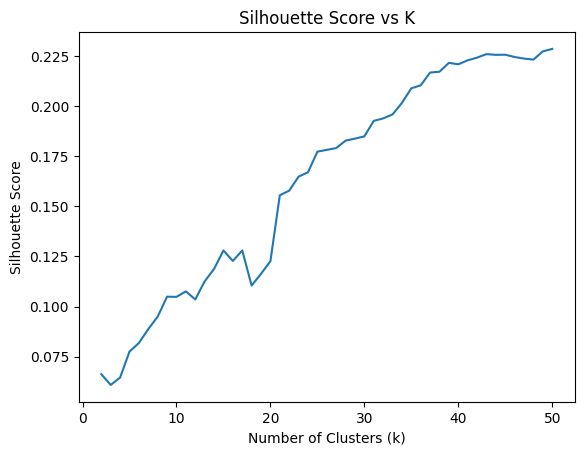

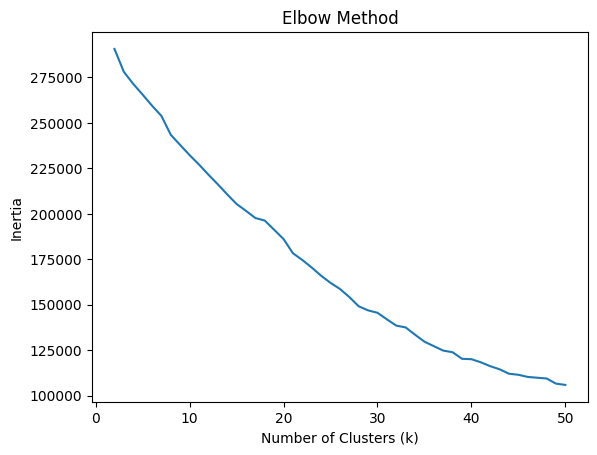

Best K (Silhouette): 50
Best Silhouette Score: 0.22862803315565183


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

sil_scores = []
inertias = []
k_values = range(2, 51)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)
    inertias.append(kmeans.inertia_)

plt.figure()
plt.plot(k_values, sil_scores)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")
plt.show()

plt.figure()
plt.plot(k_values, inertias)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

best_k = k_values[sil_scores.index(max(sil_scores))]
print("Best K (Silhouette):", best_k)
print("Best Silhouette Score:", max(sil_scores))